# EDA PASCAL VOC 2007

## Mục tiêu

Notebook này khám phá dữ liệu PASCAL VOC 2007 trước khi xây dựng dataset và huấn luyện mô hình multi-label classification. EDA tập trung vào cấu trúc split, chất lượng annotation, phân bố class, số lượng label trên mỗi ảnh, kích thước ảnh và quan hệ đồng xuất hiện giữa các class.

## Phạm vi dữ liệu

- `VOCtrainval_06-Nov-2007`: dùng hai split chính thức `train` và `val`.
- `VOCtest_06-Nov-2007`: dùng split chính thức `test`, chỉ để kiểm tra phân bố và leakage trong EDA.
- Ảnh được tham chiếu từ thư mục `JPEGImages`.
- Sau bước khởi tạo class/split, ảnh và nhãn EDA được nạp qua `PascalVOCMultiLabelDataset`.
- Dữ liệu trong `data/raw/` chỉ được đọc, không chỉnh sửa.

## Định nghĩa nhãn

Mỗi ảnh được biểu diễn bằng một tập class ở mức image-level. Nếu một class xuất hiện ở một hoặc nhiều object trong ảnh thì ảnh nhận class đó một lần. Vì vậy, nhiều object cùng class không làm tăng số label của ảnh.

Cell khởi tạo sẽ quét tên class trong annotation XML và ghi danh sách đã chuẩn hóa vào `data/processed/classes.json`. File này là artifact được sinh khi chạy notebook, không phải dữ liệu được tạo sẵn trong repository.

## Quy trình EDA

1. Đọc danh sách class từ annotation và lưu file class.
2. Tạo `PascalVOCMultiLabelDataset` cho train/val/test.
3. Đọc tensor ảnh và vector multi-hot từ dataset.
4. Kiểm tra ảnh thiếu, kích thước không hợp lệ, ảnh không có label và giao nhau giữa các split.
5. Thống kê phân bố class và số label trên mỗi ảnh.
6. Quan sát kích thước ảnh, aspect ratio và các cặp class đồng xuất hiện.

## Cách sử dụng kết quả

Các thống kê trong notebook dùng để quyết định preprocessing, cách xử lý mất cân bằng class, metric multi-label và tính phù hợp của split. Không dùng test split để điều chỉnh mô hình hoặc chọn hyperparameter.

In [30]:
from collections import Counter, defaultdict
from pathlib import Path
import json
import shutil
import sys
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt

In [31]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data.dataset import PascalVOCMultiLabelDataset
RAW_ROOT = PROJECT_ROOT / "data" / "raw"
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
VOC_TRAINVAL = RAW_ROOT / "VOCtrainval_06-Nov-2007" / "VOCdevkit" / "VOC2007"
VOC_TEST = RAW_ROOT / "VOCtest_06-Nov-2007" / "VOCdevkit" / "VOC2007"
annotation_dirs = [VOC_TRAINVAL / "Annotations", VOC_TEST / "Annotations"]
classes = sorted({
    object_node.findtext("name", "").strip()
    for annotation_dir in annotation_dirs
    for annotation_path in annotation_dir.glob("*.xml")
    for object_node in ET.parse(annotation_path).getroot().findall("object")
    if object_node.findtext("name", "").strip()
})
(PROCESSED_ROOT / "classes.json").write_text(
    json.dumps({"dataset": "PASCAL VOC 2007", "classes": classes}, indent=2) + "\n",
    encoding="utf-8",
)
class_set = set(classes)

## Lưu split chính thức

VOC2007 đã cung cấp sẵn các split `train`, `val` và `test`. Cell dưới đây chỉ sao chép nguyên văn danh sách image ID sang `data/splits/v1/`; không random lại, không thay đổi nội dung và không đọc nhãn theo từng class để tạo split mới.

Chạy cell này một lần sau khi kiểm tra đúng đường dẫn raw. Thư mục `data/splits/v1/` và ba file split sẽ được tạo bởi notebook, không được tạo sẵn thủ công.

In [32]:
SPLITS_ROOT = PROJECT_ROOT / "data" / "splits" / "v1"
official_split_sources = {
    "train": VOC_TRAINVAL / "ImageSets" / "Main" / "train.txt",
    "val": VOC_TRAINVAL / "ImageSets" / "Main" / "val.txt",
    "test": VOC_TEST / "ImageSets" / "Main" / "test.txt",
}
SPLITS_ROOT.mkdir(parents=True, exist_ok=True)
for split_name, source_path in official_split_sources.items():
    if not source_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy split chính thức: {source_path}")
    shutil.copyfile(source_path, SPLITS_ROOT / f"{split_name}.txt")

## Nạp dữ liệu qua Dataset

EDA sử dụng đúng `PascalVOCMultiLabelDataset` mà pipeline train sẽ dùng. Vì vậy label, thứ tự class, ảnh RGB và shape tensor đều được kiểm tra qua cùng một interface; notebook không parse XML lần nữa để tạo bản ghi thống kê.

In [ ]:
data_roots = {
    "train": VOC_TRAINVAL,
    "val": VOC_TRAINVAL,
    "test": VOC_TEST,
}
datasets = {
    split: PascalVOCMultiLabelDataset(
        split=split,
        data_roots=data_roots,
        splits_root=SPLITS_ROOT,
        classes_path=PROCESSED_ROOT / "classes.json",
    )
    for split in ("train", "val", "test")
}

records = []
for split, dataset in datasets.items():
    for index, image_id in enumerate(dataset.image_ids):
        image_tensor, target = dataset[index]
        records.append({
            "image_id": image_id,
            "split": split,
            "width": image_tensor.shape[2],
            "height": image_tensor.shape[1],
            "labels": [classes[i] for i, value in enumerate(target) if value.item() == 1.0],
            "image_exists": True,
        })

split_counts = Counter(record["split"] for record in records)
class_counts = Counter(label for record in records for label in record["labels"])
labels_per_image = [len(record["labels"]) for record in records]
split_counts, class_counts.most_common()

In [34]:
records = []
for split, dataset in datasets.items():
    for index, image_id in enumerate(dataset.image_ids):
        image_tensor, target = dataset[index]
        records.append({
            "image_id": image_id,
            "split": split,
            "width": image_tensor.shape[2],
            "height": image_tensor.shape[1],
            "labels": [classes[i] for i, value in enumerate(target) if value.item() == 1.0],
            "image_exists": True,
        })
split_counts = Counter(record["split"] for record in records)
class_counts = Counter(label for record in records for label in record["labels"])
labels_per_image = [len(record["labels"]) for record in records]
split_counts, class_counts.most_common()

(Counter({'test': 4952, 'val': 2510, 'train': 2501}),
 [('person', 4192),
  ('car', 1536),
  ('chair', 1117),
  ('dog', 863),
  ('sofa', 727),
  ('cat', 676),
  ('bird', 622),
  ('horse', 573),
  ('tvmonitor', 534),
  ('pottedplant', 527),
  ('train', 522),
  ('diningtable', 510),
  ('bicycle', 505),
  ('bottle', 502),
  ('motorbike', 482),
  ('aeroplane', 445),
  ('bus', 380),
  ('boat', 364),
  ('cow', 273),
  ('sheep', 195)])

## Kiểm tra chất lượng và leakage

Mục tiêu của cell dưới đây là phát hiện lỗi trước khi tạo dataset. `missing_images` cho biết annotation có nhưng ảnh tương ứng không tồn tại; `invalid_sizes` kiểm tra metadata kích thước; `empty_labels` phát hiện ảnh không có object; `split_overlap_counts` kiểm tra image ID xuất hiện đồng thời ở hai split.

Kết quả mong đợi cho một split hợp lệ là các danh sách lỗi rỗng và số lượng overlap bằng 0. Nếu có lỗi, cần dừng bước dataset để điều tra nguyên nhân thay vì âm thầm loại bỏ bản ghi.

## Phân bố class, số label và aspect ratio

Biểu đồ class giúp nhận diện mất cân bằng dữ liệu. Histogram số label trên mỗi ảnh cho biết bài toán có thực sự multi-label và mức độ phức tạp của target. Aspect ratio hỗ trợ quyết định resize/crop; nếu phân bố trải rộng, crop vuông có thể làm mất một phần object.

In [35]:
ids_by_split = defaultdict(set)
for record in records:
    ids_by_split[record["split"]].add(record["image_id"])
overlaps = {
    f"{left}/{right}": sorted(ids_by_split[left] & ids_by_split[right])
    for left, right in (("train", "val"), ("train", "test"), ("val", "test"))
}
quality_report = {
    "missing_images": [r["image_id"] for r in records if not r["image_exists"]],
    "invalid_sizes": [r["image_id"] for r in records if r["width"] <= 0 or r["height"] <= 0],
    "empty_labels": [r["image_id"] for r in records if not r["labels"]],
    "split_overlap_counts": {key: len(value) for key, value in overlaps.items()},
}
quality_report

{'missing_images': [],
 'invalid_sizes': [],
 'empty_labels': [],
 'split_overlap_counts': {'train/val': 0, 'train/test': 0, 'val/test': 0}}

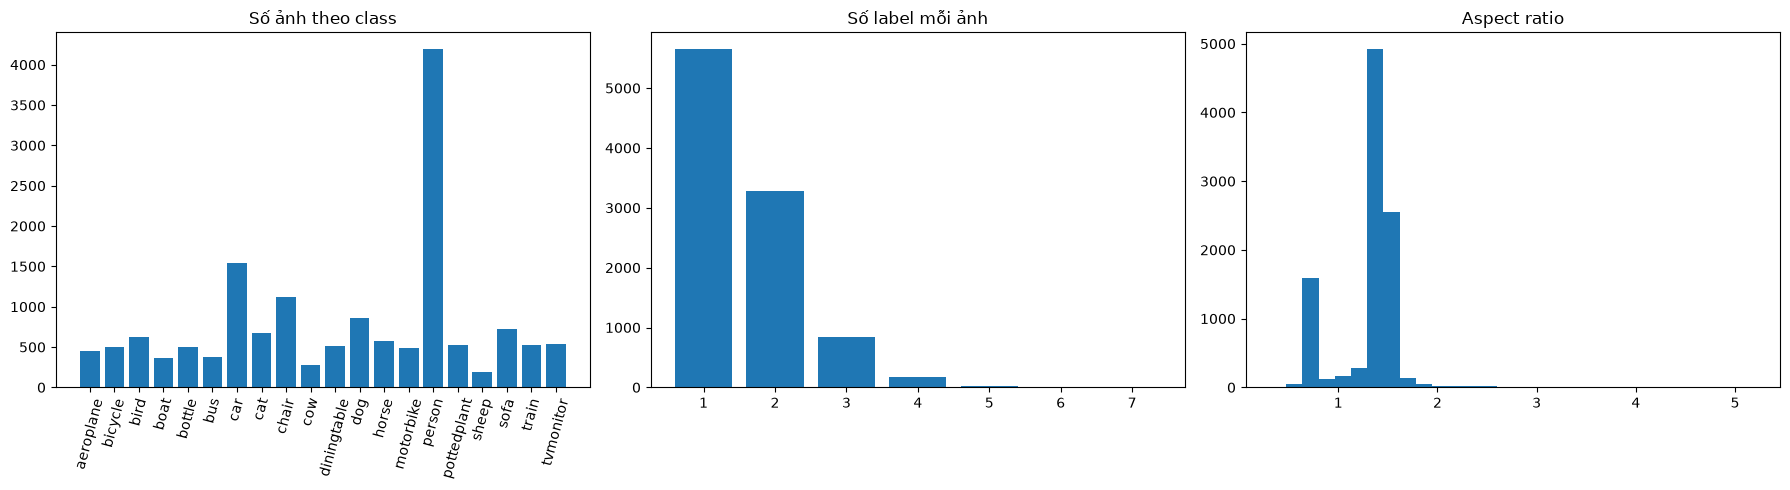

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(classes, [class_counts[name] for name in classes])
axes[0].set_title("Số ảnh theo class")
axes[0].tick_params(axis="x", rotation=75)
axes[1].hist(labels_per_image, bins=range(1, max(labels_per_image) + 2), align="left", rwidth=0.8)
axes[1].set_title("Số label mỗi ảnh")
ratios = [r["width"] / r["height"] for r in records]
axes[2].hist(ratios, bins=30)
axes[2].set_title("Aspect ratio")
plt.tight_layout()

## Đồng xuất hiện class

In [37]:
pair_counts = Counter()
for record in records:
    labels = record["labels"]
    for index, left in enumerate(labels):
        for right in labels[index + 1:]:
            pair_counts[(left, right)] += 1
sorted(pair_counts.items(), key=lambda item: item[1], reverse=True)[:20]

[(('car', 'person'), 564),
 (('chair', 'person'), 487),
 (('horse', 'person'), 448),
 (('chair', 'diningtable'), 352),
 (('motorbike', 'person'), 335),
 (('bicycle', 'person'), 334),
 (('person', 'sofa'), 323),
 (('bottle', 'person'), 311),
 (('diningtable', 'person'), 279),
 (('dog', 'person'), 251),
 (('chair', 'sofa'), 241),
 (('chair', 'tvmonitor'), 180),
 (('person', 'tvmonitor'), 179),
 (('bus', 'person'), 171),
 (('person', 'pottedplant'), 162),
 (('bus', 'car'), 160),
 (('chair', 'pottedplant'), 158),
 (('bottle', 'diningtable'), 128),
 (('boat', 'person'), 113),
 (('bottle', 'chair'), 110)]